In [34]:
from datasets import load_dataset, load_from_disk
from sklearn.model_selection import train_test_split
from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import wordnet
import numpy as np
from scipy.sparse import csr_matrix
from nltk.util import bigrams
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression, SGDClassifier
import nltk
nltk.download('punkt_tab')
nltk.download('wordnet')
lemmatizer = WordNetLemmatizer()

/home/muhannd/venv/lib/python3.12/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/muhannd/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/muhannd/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/muhannd/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [2]:
try:
    ds = load_from_disk("./datasets/emotion_dataset")
except FileNotFoundError:
    ds = load_dataset("avsolatorio/mteb-emotion-avs_triplets")
    ds.save_to_disk("./datasets/emotion_dataset")

Saving the dataset (0/1 shards):   0%|          | 0/16000 [00:00<?, ? examples/s]

In [3]:
ds['train'] # Note there is no test in this dataset only train so we treated as if it is the complete dataset

Dataset({
    features: ['text', 'label', 'label_text', 'idx', 'query_idx', 'positive_idx', 'negative_idx'],
    num_rows: 16000
})

### Split The Data

In [4]:
X_train, X_test, y_train, y_test = train_test_split(ds['train']['text'], ds['train']['label'], test_size=0.1, random_state=42)

In [5]:
len(X_train), len(X_test), len(y_train), len(y_test)

(14400, 1600, 14400, 1600)

### Data Preprocessing

In [6]:
def process_and_tokenize(x):
    arr_tokens = [word_tokenize(sentence.lower()) for sentence in x]
    for i, tokens in enumerate(arr_tokens):
       arr_tokens[i] = [token for token in tokens if token.isalpha()]

    return arr_tokens

### Lemmatization

In [7]:
def smart_lemmatize(word):
    verb_synsets = wordnet.synsets(word, pos='v')
    if verb_synsets:
        return lemmatizer.lemmatize(word, pos='v')
    return lemmatizer.lemmatize(word, pos='n')

def lemmatization(x):
    return [[smart_lemmatize(token) for token in tokens] for tokens in x]

In [8]:
X_train_tokenized = lemmatization(process_and_tokenize(X_train))

In [9]:
X_train_tokenized[1]

['i',
 'choose',
 'mouse',
 'because',
 'i',
 'feel',
 'cute',
 'a',
 'of',
 'now',
 'that',
 'i',
 'be',
 'i',
 'trip',
 'over',
 'the',
 'pile',
 'of',
 'sand',
 'repeatedly',
 'while',
 'vigorously',
 'direct']

## 2.2: Logistic Regression

#### Feature Representation

In [10]:
def to_bi_grams(x):
    vocab = {}
    for tokens in x:
        for bg in list(bigrams(tokens)):
            if bg not in vocab:
                vocab[bg] = len(vocab)

    return vocab

In [11]:
def construct_sparse_binary_vector(vocab, x):
    rows = []
    cols = []

    for row_idx, tokens in enumerate(x):
        for bg in set(bigrams(tokens)):
            col_idx = vocab.get(bg)
            if col_idx is not None:
                rows.append(row_idx)
                cols.append(col_idx)

    data = np.ones(len(rows), dtype=np.int8)

    return csr_matrix((data, (rows, cols)), shape=(len(x), len(vocab)), dtype=np.int8)

In [12]:
vocab = to_bi_grams(X_train_tokenized)
X_train_csr = construct_sparse_binary_vector(vocab, X_train_tokenized)

#### One Hot Encoding

In [13]:
encoder = OneHotEncoder(sparse_output=False)
y_train_encoded = encoder.fit_transform(np.array(y_train).reshape(-1, 1))

In [14]:
X_train_csr[0, 0]

np.int8(1)

#### Logistic Regression Implementation

In [15]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, epochs=20, batch_size=64):
        self.lr = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.W = None
        self.b = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        n_classes = y.shape[1]

        self.W = np.zeros((n_features, n_classes), dtype=np.float64)
        self.b = np.zeros((1, n_classes), dtype=np.float64)

        for epoche in range(self.epochs):
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled = y[indices]

            epoch_loss = 0.0
            num_batches = 0

            for start_batch in range(0, n_samples, self.batch_size):
                end_batch = min(start_batch + self.batch_size, n_samples)
                X_batch = X_shuffled[start_batch:end_batch]
                y_batch = y_shuffled[start_batch:end_batch]

                z_batch = X_batch.dot(self.W) + self.b

                z_exp = np.exp(z_batch - np.max(z_batch, axis=1, keepdims=True))
                p = z_exp / np.sum(z_exp, axis=1, keepdims=True)

                m = len(y_batch)
                loss = (-1.0 / m) * np.sum(np.log(p + 1e-15) * y_batch)
                epoch_loss += loss
                num_batches += 1

                dZ = (p - y_batch) / m
                dW = X_batch.T.dot(dZ)
                db = np.sum(dZ, axis=0, keepdims=True)

                self.W -= self.lr * dW
                self.b -= self.lr * db

            avg_loss = epoch_loss / num_batches
            self.loss_history.append(avg_loss)
            print(f"Epoch {epoche + 1}/{self.epochs} - Loss: {avg_loss:.4f}")

    def predict_score(self, X):
        z = X.dot(self.W) + self.b
        z_exp = np.exp(z - np.max(z, axis=1, keepdims=True))
        p = z_exp / np.sum(z_exp, axis=1, keepdims=True)
        return p

    def predict(self, X):
        z = X.dot(self.W) + self.b
        return np.argmax(z, axis=1)


In [16]:
logisticRegressionScratch = LogisticRegressionScratch(learning_rate=0.02, epochs=1000)

logisticRegressionScratch.fit(X_train_csr, y_train_encoded)

Epoch 1/1000 - Loss: 1.6693
Epoch 2/1000 - Loss: 1.5833
Epoch 3/1000 - Loss: 1.5613
Epoch 4/1000 - Loss: 1.5482
Epoch 5/1000 - Loss: 1.5376
Epoch 6/1000 - Loss: 1.5280
Epoch 7/1000 - Loss: 1.5190
Epoch 8/1000 - Loss: 1.5105
Epoch 9/1000 - Loss: 1.5023
Epoch 10/1000 - Loss: 1.4943
Epoch 11/1000 - Loss: 1.4866
Epoch 12/1000 - Loss: 1.4790
Epoch 13/1000 - Loss: 1.4716
Epoch 14/1000 - Loss: 1.4643
Epoch 15/1000 - Loss: 1.4572
Epoch 16/1000 - Loss: 1.4501
Epoch 17/1000 - Loss: 1.4432
Epoch 18/1000 - Loss: 1.4364
Epoch 19/1000 - Loss: 1.4297
Epoch 20/1000 - Loss: 1.4231
Epoch 21/1000 - Loss: 1.4166
Epoch 22/1000 - Loss: 1.4101
Epoch 23/1000 - Loss: 1.4037
Epoch 24/1000 - Loss: 1.3974
Epoch 25/1000 - Loss: 1.3912
Epoch 26/1000 - Loss: 1.3851
Epoch 27/1000 - Loss: 1.3790
Epoch 28/1000 - Loss: 1.3730
Epoch 29/1000 - Loss: 1.3670
Epoch 30/1000 - Loss: 1.3611
Epoch 31/1000 - Loss: 1.3553
Epoch 32/1000 - Loss: 1.3495
Epoch 33/1000 - Loss: 1.3438
Epoch 34/1000 - Loss: 1.3381
Epoch 35/1000 - Loss: 1

#### Testing LogisticRegressionScratch Score

In [17]:
X_test_tokens = process_and_tokenize(X_test)
X_test_lemma = lemmatization(X_test_tokens)
X_test_csr = construct_sparse_binary_vector(vocab, X_test_lemma)

In [18]:
y_predict = logisticRegressionScratch.predict(X_test_csr)

In [19]:
accuracy = np.mean(np.array(y_test) == y_predict) * 100

In [20]:
accuracy

np.float64(66.9375)

#### Comparison with scikit-learn

In [21]:
clf_lr = LogisticRegression(max_iter=1000)
clf_lr.fit(X_train_csr, y_train)
y_pred_lr = clf_lr.predict(X_test_csr)


In [22]:
clf_sgd = SGDClassifier(loss='log_loss', learning_rate='constant', eta0=0.1, max_iter=1000)
clf_sgd.fit(X_train_csr, y_train)
y_pred_sgd = clf_sgd.predict(X_test_csr)

In [23]:
acc_lr = np.mean(y_test == y_pred_lr) * 100
acc_lr

np.float64(68.125)

In [24]:
acc_sgd = np.mean(y_test == y_pred_sgd) * 100
acc_sgd

np.float64(68.0)

## 2.3: Confusion Matrix & Evaluation Metrics

#### From-Scratch Implementation

In [25]:
def confusion_matrix_scratch(y_true, y_pred, n_classes=None):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    if n_classes is None:
        n_classes = max(y_true.max(), y_pred.max()) + 1
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

In [26]:
def precision_recall_f1_scratch(cm):
    n_classes = cm.shape[0]
    precision = np.zeros(n_classes)
    recall = np.zeros(n_classes)
    f1 = np.zeros(n_classes)

    for c in range(n_classes):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp

        precision[c] = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall[c]    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1[c] = 2 * precision[c] * recall[c] / (precision[c] + recall[c]) if (precision[c] + recall[c]) > 0 else 0.0

    macro_precision = precision.mean()
    macro_recall    = recall.mean()
    macro_f1        = f1.mean()

    return precision, recall, f1, macro_precision, macro_recall, macro_f1

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(cm, label_names, title="Confusion Matrix"):
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=label_names, yticklabels=label_names, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

#### Evaluate Scratch Logistic Regression

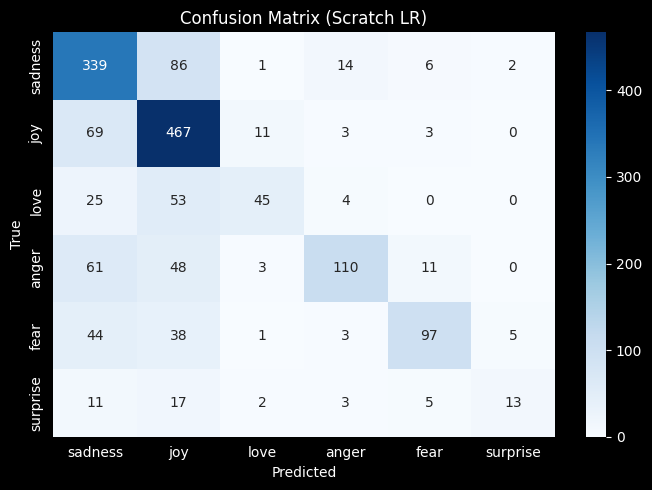

In [28]:
label_names = ["sadness", "joy", "love", "anger", "fear", "surprise"]
cm_scratch = confusion_matrix_scratch(y_test, y_predict)
plot_confusion_matrix(cm_scratch, label_names, title="Confusion Matrix (Scratch LR)")

In [29]:
prec, rec, f1_arr, macro_p, macro_r, macro_f1 = precision_recall_f1_scratch(cm_scratch)
label_names = ["sadness", "joy", "love", "anger", "fear", "surprise"]
print(f'{"Class":<12} {"Precision":>10} {"Recall":>10} {"F1-score":>10}')
print("-" * 44)
for i in range(len(prec)):
    print(f'{label_names[i]:<12} {prec[i]:>10.4f} {rec[i]:>10.4f} {f1_arr[i]:>10.4f}')
print("-" * 44)
print(f'{"Macro Avg":<12} {macro_p:>10.4f} {macro_r:>10.4f} {macro_f1:>10.4f}')

Class         Precision     Recall   F1-score
--------------------------------------------
sadness          0.6175     0.7567     0.6800
joy              0.6587     0.8445     0.7401
love             0.7143     0.3543     0.4737
anger            0.8029     0.4721     0.5946
fear             0.7951     0.5160     0.6258
surprise         0.6500     0.2549     0.3662
--------------------------------------------
Macro Avg        0.7064     0.5331     0.5801


#### Comparison with scikit-learn

In [30]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

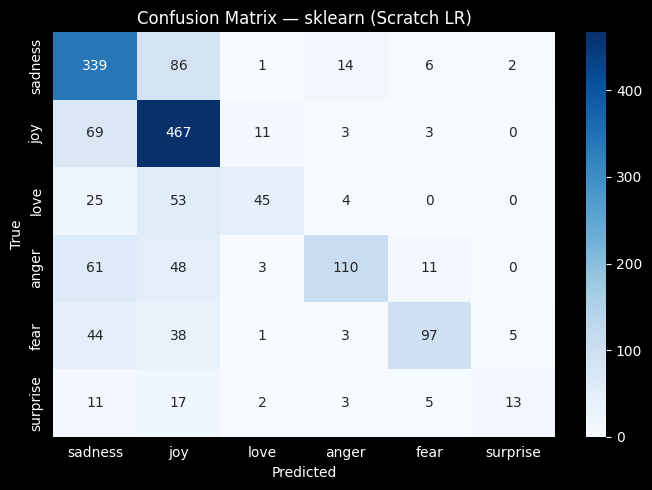

Matrices match: True


In [31]:
cm_sk = confusion_matrix(y_test, y_predict)
plot_confusion_matrix(cm_sk, label_names, title="Confusion Matrix — sklearn (Scratch LR)")
print(f"Matrices match: {np.array_equal(cm_scratch, cm_sk)}")

In [32]:
print("Scratch LR — sklearn metrics vs from-scratch:")
print(f'{"Metric":<20} {"sklearn":>10} {"Scratch":>10}')
print("-" * 42)
print(f'{"Macro Precision":<20} {precision_score(y_test, y_predict, average="macro"):>10.4f} {macro_p:>10.4f}')
print(f'{"Macro Recall":<20} {recall_score(y_test, y_predict, average="macro"):>10.4f} {macro_r:>10.4f}')
print(f'{"Macro F1":<20} {f1_score(y_test, y_predict, average="macro"):>10.4f} {macro_f1:>10.4f}')

Scratch LR — sklearn metrics vs from-scratch:
Metric                  sklearn    Scratch
------------------------------------------
Macro Precision          0.7064     0.7064
Macro Recall             0.5331     0.5331
Macro F1                 0.5801     0.5801


#### Evaluate sklearn LogisticRegression & SGDClassifier

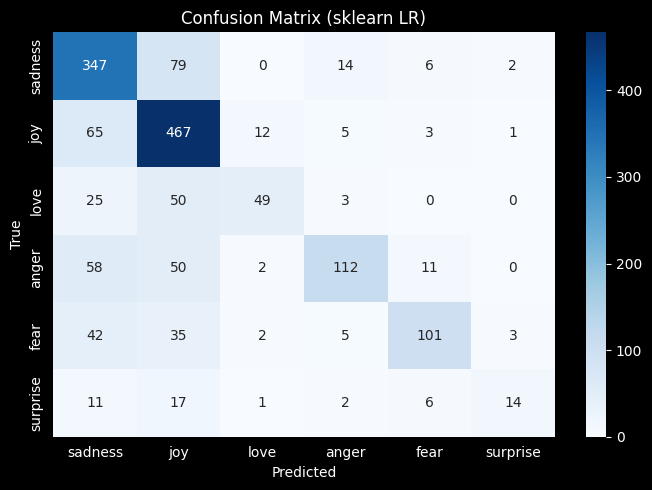


Class         Precision     Recall   F1-score
--------------------------------------------
sadness          0.6332     0.7746     0.6968
joy              0.6691     0.8445     0.7466
love             0.7424     0.3858     0.5078
anger            0.7943     0.4807     0.5989
fear             0.7953     0.5372     0.6413
surprise         0.7000     0.2745     0.3944
--------------------------------------------
Macro Avg        0.7224     0.5495     0.5976


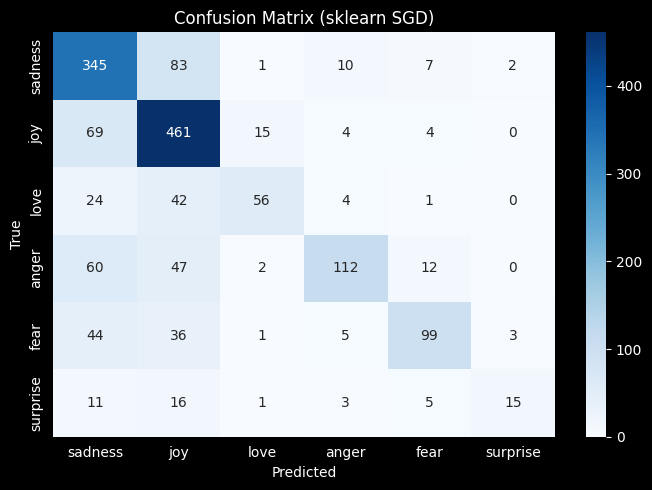


Class         Precision     Recall   F1-score
--------------------------------------------
sadness          0.6239     0.7701     0.6893
joy              0.6730     0.8336     0.7447
love             0.7368     0.4409     0.5517
anger            0.8116     0.4807     0.6038
fear             0.7734     0.5266     0.6266
surprise         0.7500     0.2941     0.4225
--------------------------------------------
Macro Avg        0.7281     0.5577     0.6064


In [33]:
for name, preds in [("sklearn LR", y_pred_lr), ("sklearn SGD", y_pred_sgd)]:
    cm = confusion_matrix_scratch(y_test, preds)
    p, r, f, mp, mr, mf = precision_recall_f1_scratch(cm)
    plot_confusion_matrix(cm, label_names, title=f"Confusion Matrix ({name})")
    print(f'\n{"Class":<12} {"Precision":>10} {"Recall":>10} {"F1-score":>10}')
    print("-" * 44)
    for i in range(len(p)):
        print(f'{label_names[i]:<12} {p[i]:>10.4f} {r[i]:>10.4f} {f[i]:>10.4f}')
    print("-" * 44)
    print(f'{"Macro Avg":<12} {mp:>10.4f} {mr:>10.4f} {mf:>10.4f}')